### **Project Summary: Arrhythmia Classification & Dimensionality Reduction Pipeline**

This notebook documents an end-to-end machine learning and data analysis pipeline for predicting arrhythmia types using the UCI Arrhythmia dataset.

#### **1. Data Loading and Initial Exploration**
* **Loaded Dataset:** Imported `/content/arrhythmia.csv` with no headers, consisting of **452 rows** and **280 columns**.
* **Statistical Profiles:** Analyzed dataset characteristics using `.head()`, `.tail()`, `.describe()`, and `.info()` which identified numeric types (`float64`, `int64`) and some `object` columns.

#### **2. Data Cleaning & Handling Missing Values**
* **Handling Placeholder Values:** Identified that missing values were represented as `'?'`. Replaced `'?'` with `np.nan`, revealing **408** total missing values.
* **Missing Value Analysis:** Plotted the distribution of null values across columns. Column `13` (representing J wave axis) had the highest missing rate (376 missing values).
* **Feature Dropping:** Dropped column `13` entirely due to the extreme missing rate.
* **Missing Indicator Flags:** Added binary indicator columns for columns containing missing values to preserve the variance information of the missingness.
* **Imputation:** Applied `SimpleImputer` using the default mean strategy to handle remaining missing values in the features.

#### **3. Feature Renaming & Target Isolation**
* **Header Mapping:** Assigned descriptive clinical column names (e.g., `Age`, `Sex`, `Height`, `Weight`, QRS/PR/QT intervals, specific waves, and ECG lead variables) mapped to the target variable `class`.
* **Exported Data:** Saved the prepared, imputed DataFrame to `/content/new_data_with target_class`.
* **Isolated Target:** Separated features (`final_df` containing 278 columns) and target labels (`target`).

#### **4. Exploratory Data Analysis & Visualizations**
* **Class Balance:** Visualized the target `class` distribution using a Seaborn count plot. Handled logarithmic normalization plots for heavily imbalanced classes.
* **Biometrics Grid:** Plotted a Seaborn `PairGrid` of `Age`, `Sex`, `Height`, and `Weight` mapped by gender, highlighting a outlier height value of `780.0`.
* **ECG Interval Boxplots:** Created box plots for interval distributions (`QRS_Dur`, `P-R_Int`, `Q-T_Int`, `T_Int`, `P_Int`) and ECG leads (AVR, AVL, AVF) to detect outlier features.

#### **5. Model Training & Baseline Evaluation**
* **Splitting:** Segmented the data into an 80/20 train-test split with a fixed random seed.
* **Scaling:** Standardized the features using `StandardScaler` to bring them onto the same scale.
* **Metrics Setup:** Dynamically patched `scipy.interp = np.interp` to ensure compatibility with `scikit-plot` metrics.
* **Model Benchmarking:** Evaluated 5 major classifiers (KNN, Logistic Regression, Decision Tree, Linear SVC, and Random Forest). Calculated and logged training and testing accuracies to compare baseline performances.

#### **6. Dimensionality Reduction with PCA**
* **Variance Retention:** Fit PCA retaining **98%** of the variance, reducing the dimensionality from 278 features down to **121 principal components**.
* **PCA Classifiers:** Evaluated the same classifiers on the PCA-reduced space and stored performance in `result_with_pca`.
* **Visualization:** Plotted bar charts comparing the training and testing performances of baseline classifiers versus their PCA-reduced counterparts.

In [120]:
from ast import increment_lineno
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import math as mt
import scipy as sp
%matplotlib inline
from sklearn.impute import SimpleImputer

In [121]:
df = pd.read_csv('/content/arrhythmia.csv',header = None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
0,75,0,190,80,91,193,371,174,121,-16,...,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8
1,56,1,165,64,81,174,401,149,39,25,...,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6
2,54,0,172,95,138,163,386,185,102,96,...,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10
3,55,0,175,94,100,202,380,179,143,28,...,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1
4,75,0,190,80,88,181,360,177,103,-16,...,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7


In [122]:
df.tail()

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
447,53,1,160,70,80,199,382,154,117,-37,...,0.0,4.3,-5.0,0.0,0.0,0.7,0.6,-4.4,-0.5,1
448,37,0,190,85,100,137,361,201,73,86,...,0.0,15.6,-1.6,0.0,0.0,0.4,2.4,38.0,62.4,10
449,36,0,166,68,108,176,365,194,116,-85,...,0.0,16.3,-28.6,0.0,0.0,1.5,1.0,-44.2,-33.2,2
450,32,1,155,55,93,106,386,218,63,54,...,-0.4,12.0,-0.7,0.0,0.0,0.5,2.4,25.0,46.6,1
451,78,1,160,70,79,127,364,138,78,28,...,0.0,10.4,-1.8,0.0,0.0,0.5,1.6,21.3,32.8,1


In [123]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
count,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,...,452.000000,452.000000,452.000000,452.000000,452.0,452.000000,452.000000,452.000000,452.000000,452.000000
mean,46.471239,0.550885,166.188053,68.170354,88.920354,155.152655,367.207965,169.949115,90.004425,33.676991,...,-0.278982,9.048009,-1.457301,0.003982,0.0,0.514823,1.222345,19.326106,29.473230,3.880531
std,16.466631,0.497955,37.170340,16.590803,15.364394,44.842283,33.385421,35.633072,25.826643,45.431434,...,0.548876,3.472862,2.002430,0.050118,0.0,0.347531,1.426052,13.503922,18.493927,4.407097
min,0.000000,0.000000,105.000000,6.000000,55.000000,0.000000,232.000000,108.000000,0.000000,-172.000000,...,-4.100000,0.000000,-28.600000,0.000000,0.0,-0.800000,-6.000000,-44.200000,-38.600000,1.000000
25%,36.000000,0.000000,160.000000,59.000000,80.000000,142.000000,350.000000,148.000000,79.000000,3.750000,...,-0.425000,6.600000,-2.100000,0.000000,0.0,0.400000,0.500000,11.450000,17.550000,1.000000
50%,47.000000,1.000000,164.000000,68.000000,86.000000,157.000000,367.000000,162.000000,91.000000,40.000000,...,0.000000,8.800000,-1.100000,0.000000,0.0,0.500000,1.350000,18.100000,27.900000,1.000000
75%,58.000000,1.000000,170.000000,79.000000,94.000000,175.000000,384.000000,179.000000,102.000000,66.000000,...,0.000000,11.200000,0.000000,0.000000,0.0,0.700000,2.100000,25.825000,41.125000,6.000000
max,83.000000,1.000000,780.000000,176.000000,188.000000,524.000000,509.000000,381.000000,205.000000,169.000000,...,0.000000,23.600000,0.000000,0.800000,0.0,2.400000,6.000000,88.800000,115.900000,16.000000


In [124]:
df.shape

(452, 280)

In [125]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 452 entries, 0 to 451
Columns: 280 entries, 0 to 279
dtypes: float64(120), int64(155), object(5)
memory usage: 988.9+ KB


In [126]:
df.isnull().sum()

,0
0,0
1,0
2,0
3,0
4,0
...,...
275,0
276,0
277,0
278,0


In [127]:
pd.isnull(df).sum().sum()

np.int64(0)

In [128]:
df= df.replace('?',np.nan)

In [129]:
na = pd.isnull(df).sum().sum()
na

np.int64(408)

Text(0, 0.5, 'total no null value in each rows')

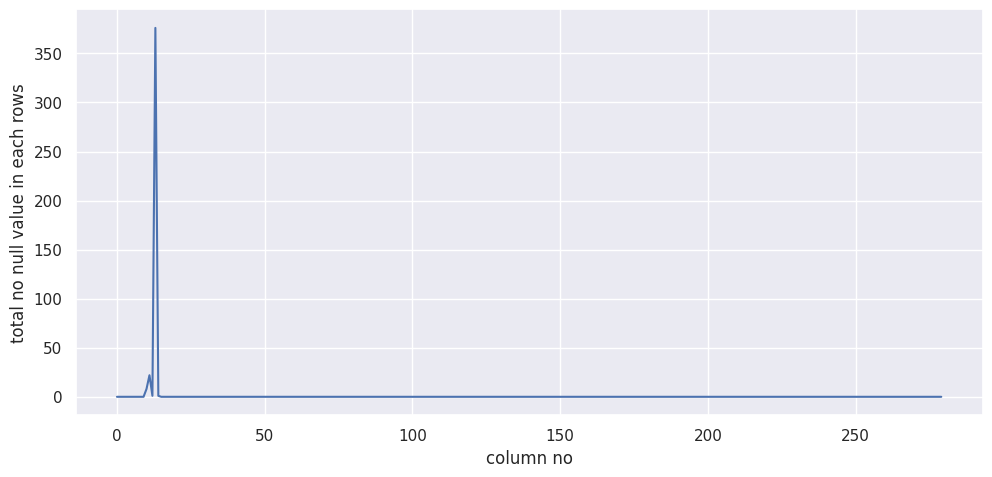

In [130]:
pd.isnull(df).sum().plot()
plt.xlabel('column no')
plt.ylabel('total no null value in each rows')

<Axes: >

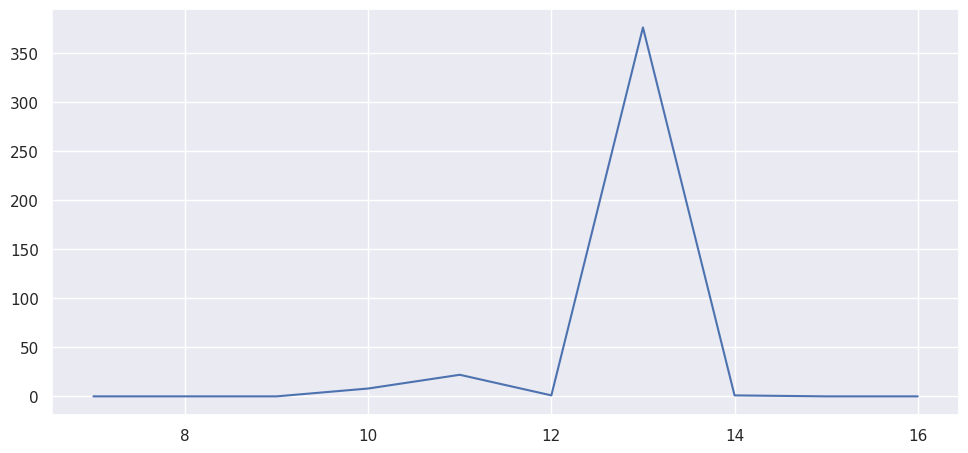

In [131]:
pd.isnull(df).sum()[7:17].plot()

In [132]:
df.drop(columns = 13,inplace = True)

In [133]:
new_df = df.copy()

In [134]:
new_df.head()

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
0,75,0,190,80,91,193,371,174,121,-16,...,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8
1,56,1,165,64,81,174,401,149,39,25,...,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6
2,54,0,172,95,138,163,386,185,102,96,...,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10
3,55,0,175,94,100,202,380,179,143,28,...,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1
4,75,0,190,80,88,181,360,177,103,-16,...,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7


In [135]:
col_with_mising_value = (col for col in new_df.columns if new_df[col].isnull().any())
for col in col_with_mising_value:
  new_df[col] = new_df[col].isnull()

In [136]:
inpute = SimpleImputer()
new_df = pd.DataFrame(inpute.fit_transform(new_df))
new_df.columns = df.columns

In [137]:
new_df.head()

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
0,75.0,0.0,190.0,80.0,91.0,193.0,371.0,174.0,121.0,-16.0,...,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8.0
1,56.0,1.0,165.0,64.0,81.0,174.0,401.0,149.0,39.0,25.0,...,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6.0
2,54.0,0.0,172.0,95.0,138.0,163.0,386.0,185.0,102.0,96.0,...,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10.0
3,55.0,0.0,175.0,94.0,100.0,202.0,380.0,179.0,143.0,28.0,...,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1.0
4,75.0,0.0,190.0,80.0,88.0,181.0,360.0,177.0,103.0,-16.0,...,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7.0


In [138]:
pd.isnull(new_df).sum().sum()

np.int64(0)

In [139]:
final_df_columns=["Age","Sex","Height","Weight","QRS_Dur",
"P-R_Int","Q-T_Int","T_Int","P_Int","QRS","T","P","J","Heart_Rate",
"Q_Wave","R_Wave","S_Wave","R'_Wave","S'_Wave","Int_Def","Rag_R_Nom",
"Diph_R_Nom","Rag_P_Nom","Diph_P_Nom","Rag_T_Nom","Diph_T_Nom",
"DII00", "DII01","DII02", "DII03", "DII04","DII05","DII06","DII07","DII08","DII09","DII10","DII11",
"DIII00","DIII01","DIII02", "DIII03", "DIII04","DIII05","DIII06","DIII07","DIII08","DIII09","DIII10","DIII11",
"AVR00","AVR01","AVR02","AVR03","AVR04","AVR05","AVR06","AVR07","AVR08","AVR09","AVR10","AVR11",
"AVL00","AVL01","AVL02","AVL03","AVL04","AVL05","AVL06","AVL07","AVL08","AVL09","AVL10","AVL11",
"AVF00","AVF01","AVF02","AVF03","AVF04","AVF05","AVF06","AVF07","AVF08","AVF09","AVF10","AVF11",
"V100","V101","V102","V103","V104","V105","V106","V107","V108","V109","V110","V111",
"V200","V201","V202","V203","V204","V205","V206","V207","V208","V209","V210","V211",
"V300","V301","V302","V303","V304","V305","V306","V307","V308","V309","V310","V311",
"V400","V401","V402","V403","V404","V405","V406","V407","V408","V409","V410","V411",
"V500","V501","V502","V503","V504","V505","V506","V507","V508","V509","V510","V511",
"V600","V601","V602","V603","V604","V605","V606","V607","V608","V609","V610","V611",
"JJ_Wave","Amp_Q_Wave","Amp_R_Wave","Amp_S_Wave","R_Prime_Wave","S_Prime_Wave","P_Wave","T_Wave",
"QRSA","QRSTA","DII170","DII171","DII172","DII173","DII174","DII175","DII176","DII177","DII178","DII179",
"DIII180","DIII181","DIII182","DIII183","DIII184","DIII185","DIII186","DIII187","DIII188","DIII189",
"AVR190","AVR191","AVR192","AVR193","AVR194","AVR195","AVR196","AVR197","AVR198","AVR199",
"AVL200","AVL201","AVL202","AVL203","AVL204","AVL205","AVL206","AVL207","AVL208","AVL209",
"AVF210","AVF211","AVF212","AVF213","AVF214","AVF215","AVF216","AVF217","AVF218","AVF219",
"V1220","V1221","V1222","V1223","V1224","V1225","V1226","V1227","V1228","V1229",
"V2230","V2231","V2232","V2233","V2234","V2235","V2236","V2237","V2238","V2239",
"V3240","V3241","V3242","V3243","V3244","V3245","V3246","V3247","V3248","V3249",
"V4250","V4251","V4252","V4253","V4254","V4255","V4256","V4257","V4258","V4259",
"V5260","V5261","V5262","V5263","V5264","V5265","V5266","V5267","V5268","V5269",
"V6270","V6271","V6272","V6273","V6274","V6275","V6276","V6277","V6278","V6279","class"]
#Adding Column names to dataset

In [140]:
new_df.columns =final_df_columns
new_df.to_csv('new_data_with target_class')
new_df.head()

,Age,Sex,Height,Weight,QRS_Dur,P-R_Int,Q-T_Int,T_Int,P_Int,QRS,...,V6271,V6272,V6273,V6274,V6275,V6276,V6277,V6278,V6279,class
0,75.0,0.0,190.0,80.0,91.0,193.0,371.0,174.0,121.0,-16.0,...,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8.0
1,56.0,1.0,165.0,64.0,81.0,174.0,401.0,149.0,39.0,25.0,...,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6.0
2,54.0,0.0,172.0,95.0,138.0,163.0,386.0,185.0,102.0,96.0,...,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10.0
3,55.0,0.0,175.0,94.0,100.0,202.0,380.0,179.0,143.0,28.0,...,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1.0
4,75.0,0.0,190.0,80.0,88.0,181.0,360.0,177.0,103.0,-16.0,...,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7.0


In [141]:
target = new_df['class']


In [142]:
final_df =new_df.drop(columns = 'class')

In [143]:
print(final_df.shape)
print(target.shape)

(452, 278)
(452,)


In [144]:
class_names = ["Normal",
               "Ischemic changes (CAD)",
               "Old Anterior Myocardial Infraction",
               "Old Inferior Myocardial Infraction",
               "Sinus tachycardy",
               "Sinus bradycardy",
               "Ventricular Premature Contraction (PVC)",
               "Supraventricular Premature Contraction",
               "Left Boundle branch block",
               "Right boundle branch block",
               "1.Degree AtrioVentricular block",
               "2.Degree AV block",
               "3.Degree AV block",
               "Left Ventricule hypertrophy",
               "Atrial Fibrillation or Flutter",
               "Others"]

In [145]:
t =new_df.sort_values(by = ['class'])

In [146]:
la = t['class'].value_counts(sort = False).tolist()

<Axes: xlabel='class', ylabel='count'>

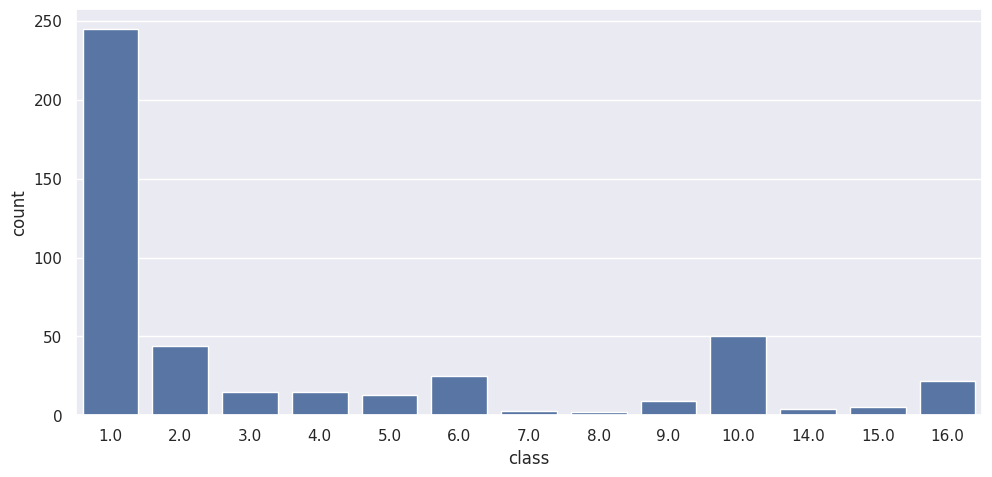

In [147]:
sns.countplot(x='class', data=new_df)


In [148]:
values= la[0:10]
values.extend([0,0,0])
values.extend(la[10:13
                 ])
print(values)


[245, 44, 15, 15, 13, 25, 3, 2, 9, 50, 0, 0, 0, 4, 5, 22]


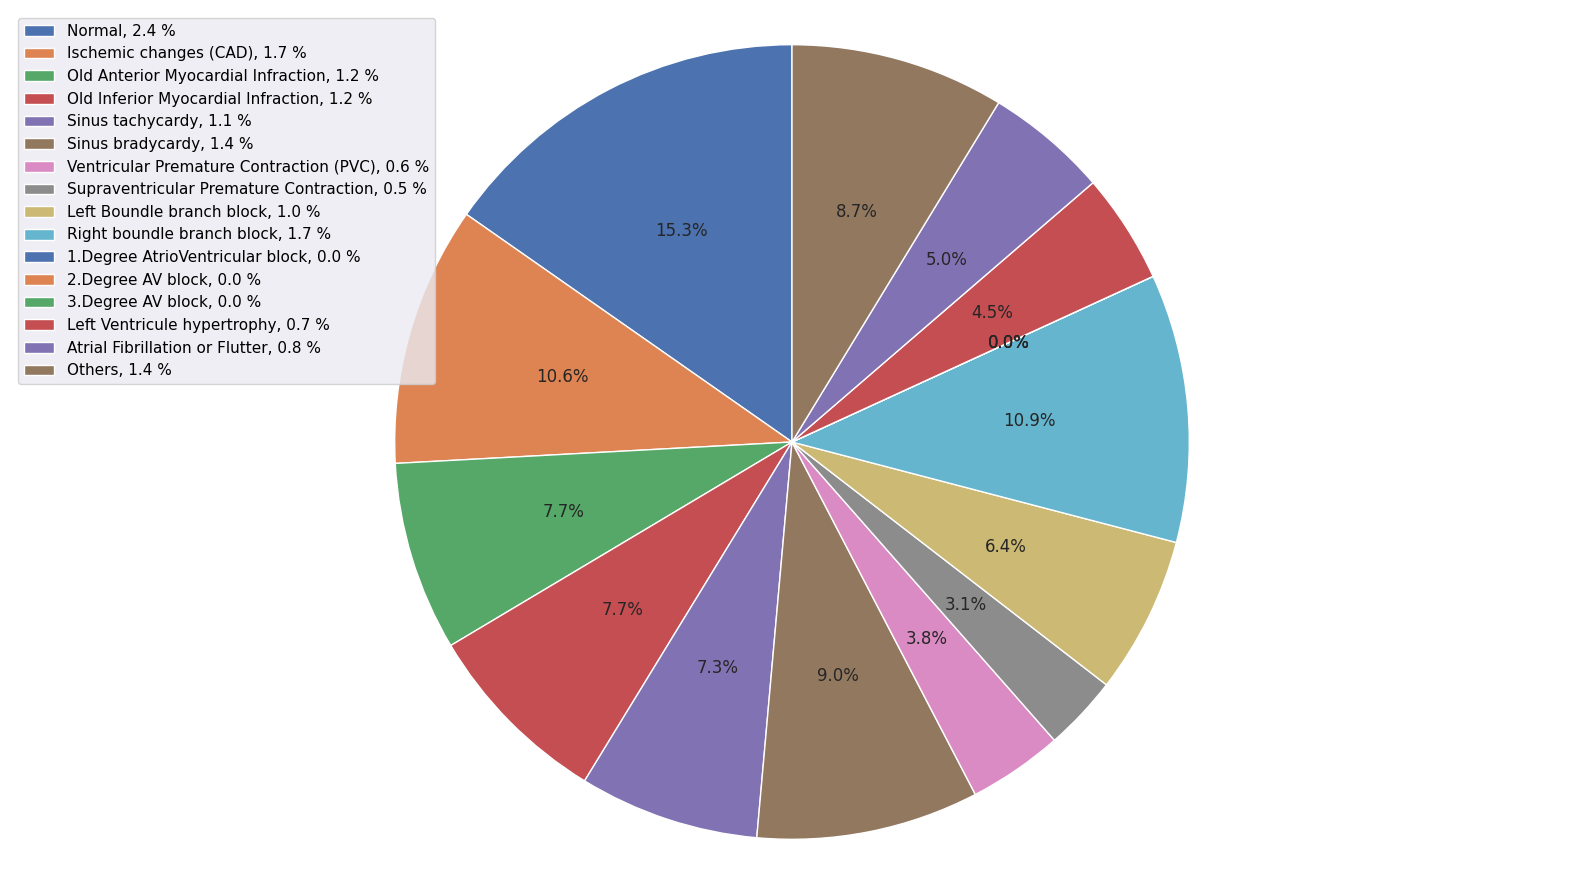

In [149]:
labels = class_names
log_norm = []
for i in values:
  log_norm.append(mt.log10(i + 1))

fig1, ax1 = plt.subplots(figsize=(16, 9))
patches, texts, autotexts = plt.pie(log_norm, autopct='%1.1f%%', startangle=90)

leg = plt.legend(loc='best', labels=['%s, %1.1f %%' % (l, s) for l, s in zip(labels, log_norm)])
plt.axis('equal')

for text in leg.get_texts():
  plt.setp(text, color='black')
plt.tight_layout()
plt.show()

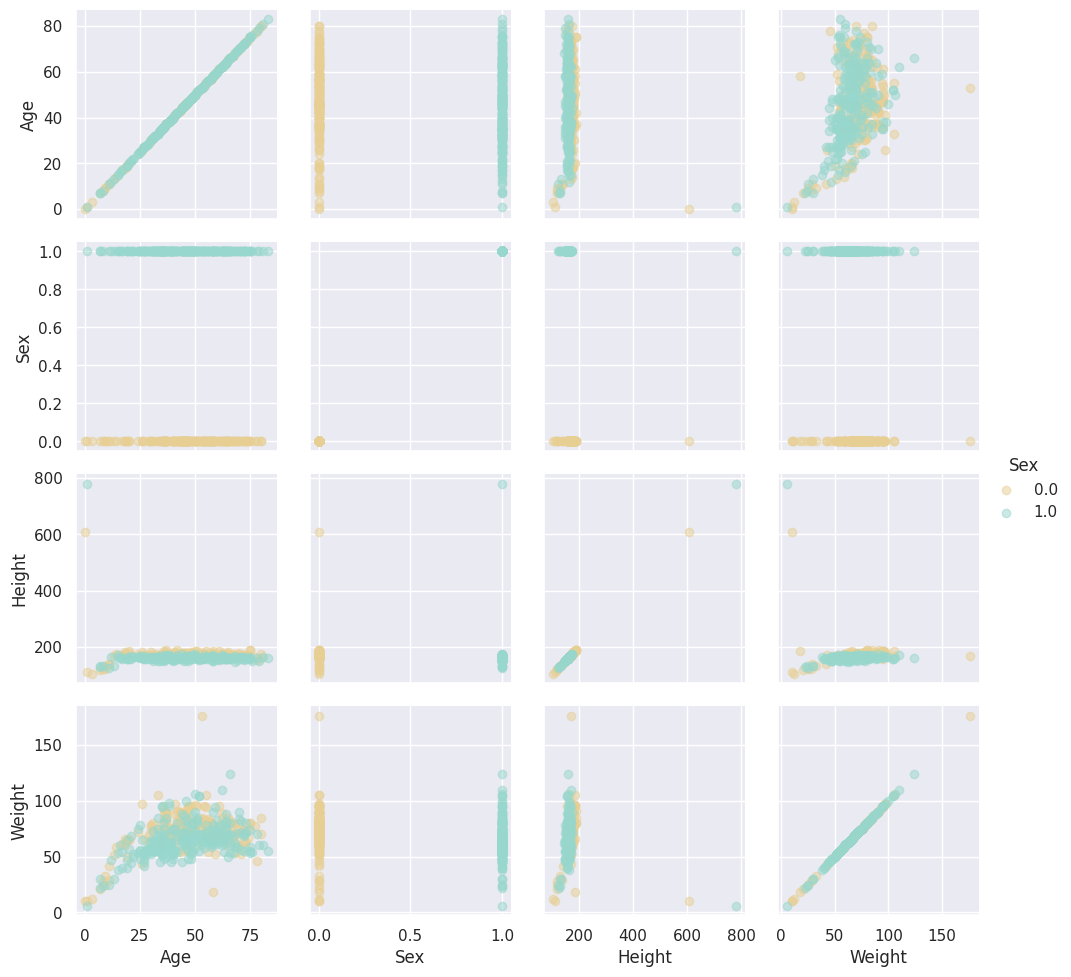

In [150]:
g = sns.PairGrid(final_df,vars = ['Age','Sex','Height','Weight'],hue = 'Sex',palette = 'BrBG')
g.map(plt.scatter,alpha = 0.5)
g.add_legend()
plt.show()

In [151]:
sorted(final_df['Height'] , reverse = True)[:10]

[780.0, 608.0, 190.0, 190.0, 190.0, 188.0, 186.0, 186.0, 186.0, 185.0]

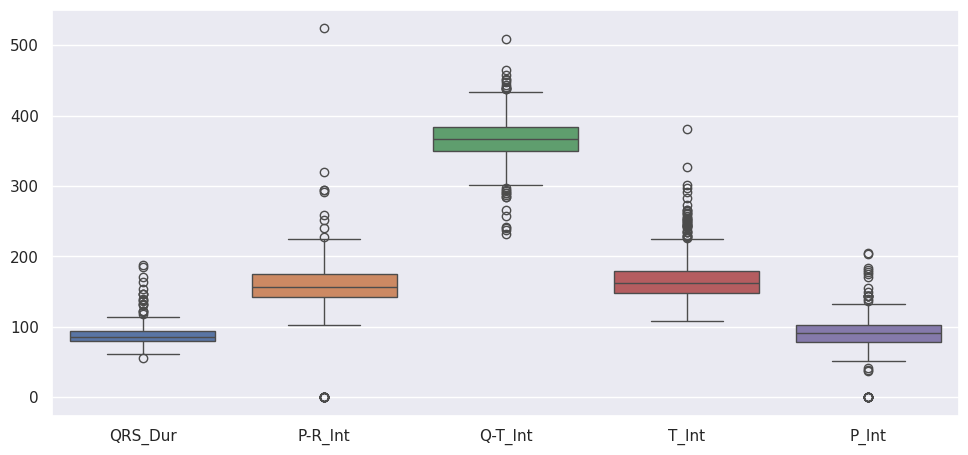

In [152]:
sns.boxplot(data = new_df[['QRS_Dur',"P-R_Int","Q-T_Int","T_Int","P_Int"]]);

<Axes: xlabel='P-R_Int'>

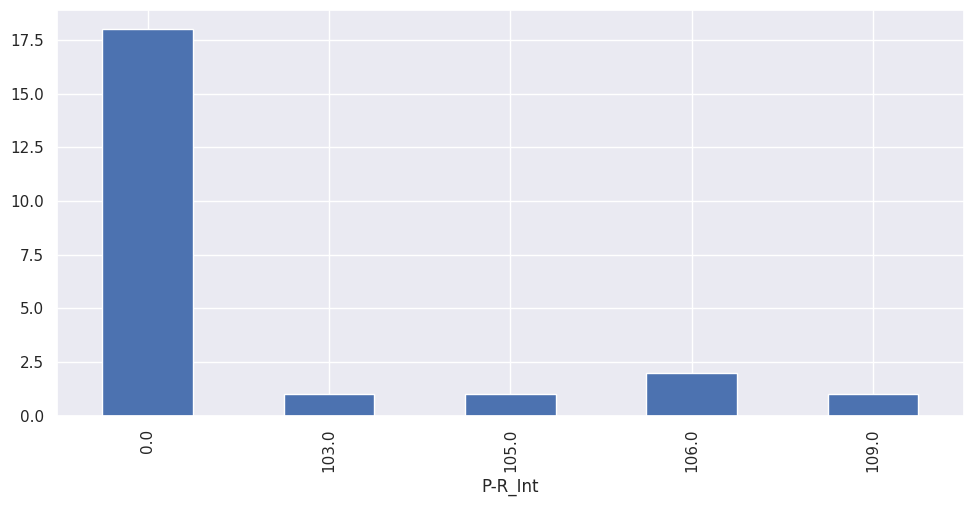

In [153]:
new_df['P-R_Int'].value_counts().sort_index().head().plot(kind = 'bar')

<Axes: xlabel='P-R_Int'>

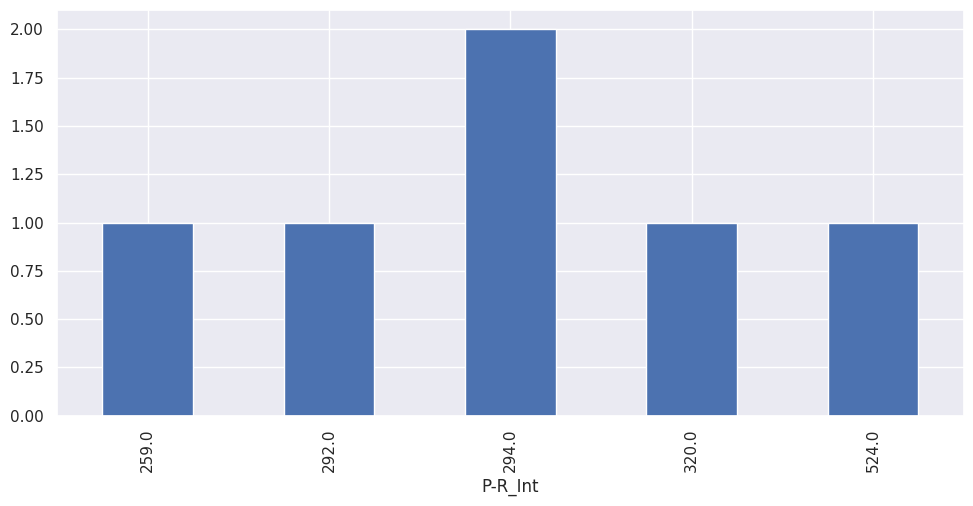

In [154]:
final_df['P-R_Int'].value_counts().sort_index().tail().plot(kind='bar')

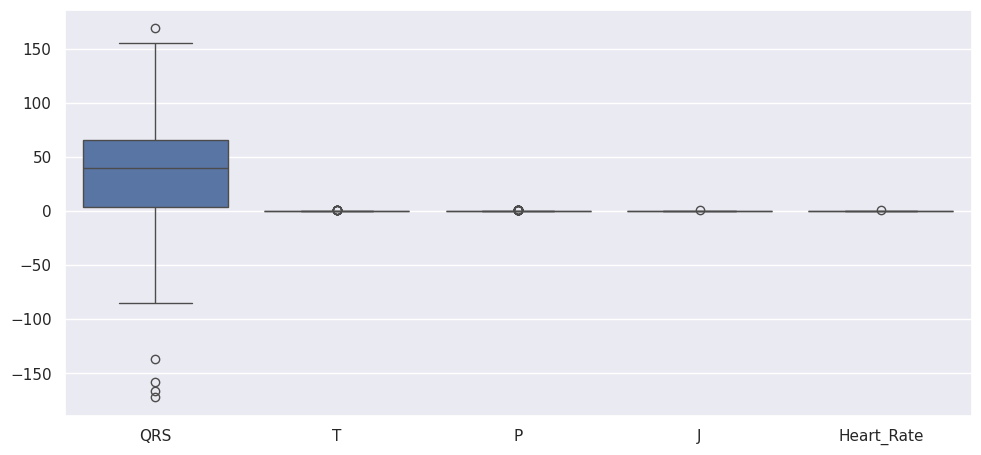

In [155]:
sns.boxplot(data=final_df[["QRS","T","P","J","Heart_Rate"]]);

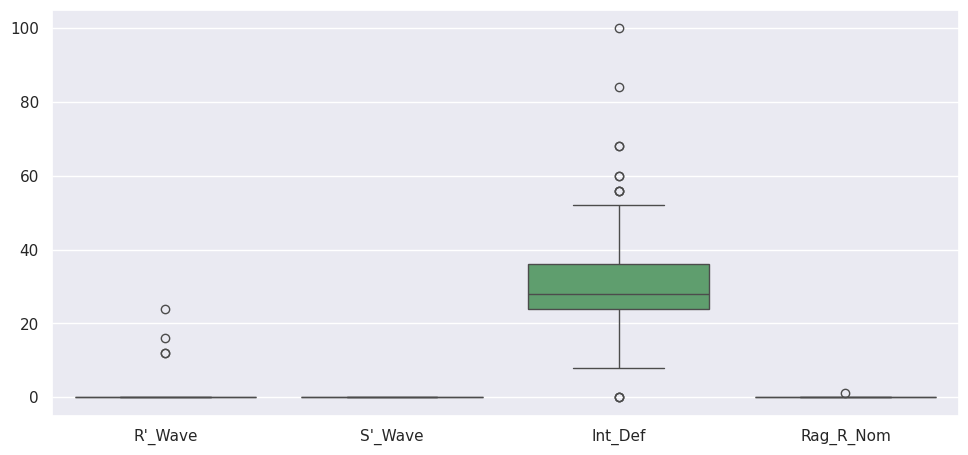

In [156]:
sns.boxplot(data=final_df[["R'_Wave","S'_Wave","Int_Def","Rag_R_Nom"]]);

In [157]:
final_df["V101"].unique()

array([  0.,  24.,  36.,  20.,  44.,  28.,  16.,  32.,  48.,  40.,  12.,
        64., 112., 216.,  84.,  72.,  68.])

In [158]:
final_df["S'_Wave"].value_counts().sort_index(ascending=False)

,count
S'_Wave,
0.0,452


In [159]:
final_df["V101"].value_counts().sort_index(ascending=False)

,count
V101,
216.0,1
112.0,1
84.0,1
72.0,1
68.0,1
64.0,1
48.0,6
44.0,6
40.0,13


In [160]:
final_df["V201"].value_counts().sort_index(ascending=False)

,count
V201,
216.0,1
136.0,1
84.0,1
72.0,1
60.0,5
56.0,4
52.0,12
48.0,19
44.0,53


In [161]:
final_df["V301"].value_counts().sort_index(ascending=False)

,count
V301,
132.0,1
88.0,2
76.0,2
72.0,1
68.0,2
64.0,3
60.0,16
56.0,26
52.0,57


In [162]:
final_df["V501"].value_counts().sort_index(ascending=False)

,count
V501,
136.0,1
120.0,2
116.0,1
108.0,1
96.0,1
92.0,1
84.0,1
76.0,2
72.0,3


<Axes: >

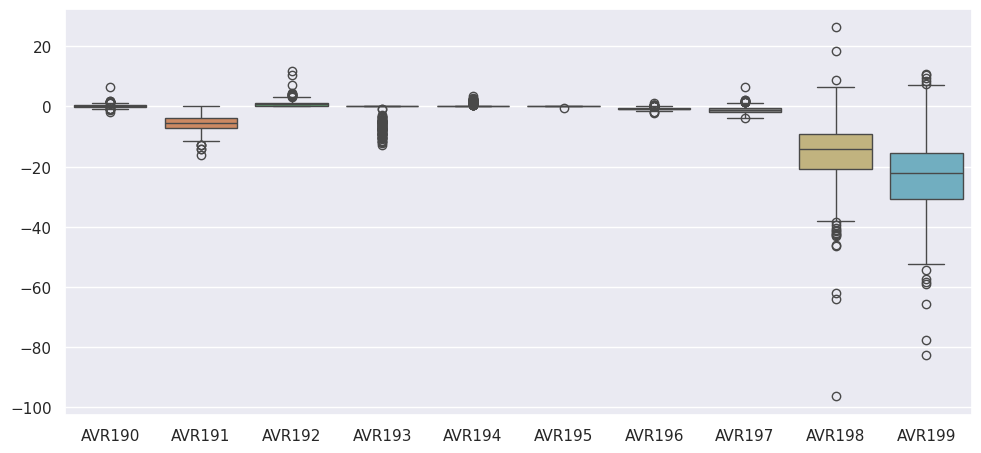

In [163]:
sns.set(rc={'figure.figsize':(11.7,5.27)})
sns.boxplot(data=final_df[["AVR190","AVR191","AVR192","AVR193","AVR194","AVR195","AVR196","AVR197","AVR198","AVR199"]])

<Axes: >

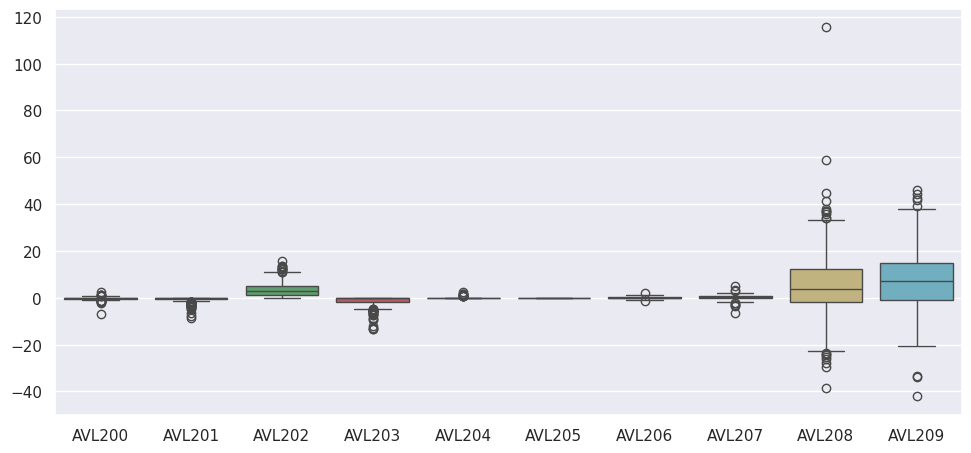

In [164]:
sns.set(rc={'figure.figsize':(11.7,5.27)})
sns.boxplot(data=final_df[["AVL200","AVL201","AVL202","AVL203","AVL204","AVL205","AVL206","AVL207","AVL208","AVL209"]])

<Axes: >

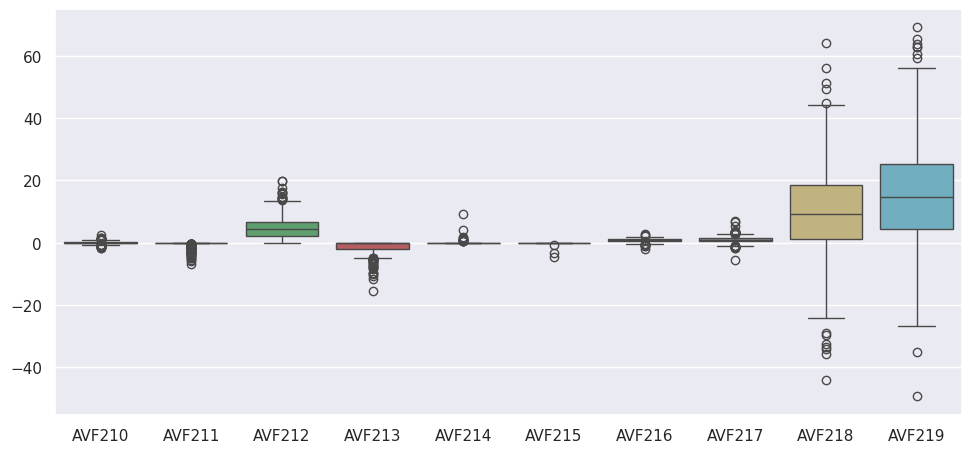

In [165]:
sns.set(rc={'figure.figsize':(11.7,5.27)})
sns.boxplot(data=final_df[["AVF210","AVF211","AVF212","AVF213","AVF214","AVF215","AVF216","AVF217","AVF218","AVF219"]])

In [166]:
pearson_corr = final_df.corrwith(other = target, method = 'pearson')

In [167]:
pearson_corr.values

array([-9.23812218e-02, -1.78080037e-01,  6.64802711e-03, -9.01507390e-02,
        3.23878728e-01, -9.99540161e-02,  2.83049762e-02,  9.76253981e-02,
       -1.22002504e-01,  1.95854526e-02, -1.68648870e-04,  1.90644217e-01,
       -3.08114850e-02,  3.33672764e-02,  3.96491896e-03,  4.26738126e-02,
        1.95198200e-01,  6.39992472e-02,             nan,  4.27635327e-02,
       -2.01150248e-02,  7.67517615e-03, -3.55694451e-02,  3.20969797e-02,
        3.20969797e-02,  8.30559434e-02, -3.61168680e-03,  4.83674292e-02,
        1.83082712e-01, -1.05049431e-02,  6.65428889e-02,  6.77662940e-02,
        4.17574601e-02,  7.98435069e-02, -2.01150248e-02,  1.69531020e-02,
       -3.60504699e-02, -6.66334979e-04, -2.36687153e-02,  1.16515578e-01,
        8.16735582e-02,  1.44307782e-02, -3.20137575e-02,  8.34076694e-02,
       -3.08114850e-02,  5.14341059e-02, -3.08114850e-02, -8.40208668e-02,
       -1.15446555e-02, -5.76271452e-03,  2.10381327e-02,  1.73243101e-01,
        2.54790200e-03,  

In [168]:
x = final_df
y = target

In [169]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 1)

In [170]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [171]:
import warnings
warnings.filterwarnings('ignore')


In [172]:
!pip install scikit-plot
import numpy as np
import scipy
# Patch the deprecated scipy.interp with numpy.interp so scikit-plot can import it successfully
scipy.interp = np.interp

from sklearn.metrics import accuracy_score,confusion_matrix,r2_score,mean_squared_error,recall_score,precision_score,f1_score,classification_report
from scikitplot.metrics import plot_confusion_matrix,plot_roc

In [173]:
result = pd.DataFrame(columns = ['model','train_accuracy','test_ccuracy'])


In [174]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

In [175]:
model = {
    'KNN Classifier' : KNeighborsClassifier(),
    'Logestic Regression	' :LogisticRegression(solver = 'saga', random_state=0),
    'Decision Tree Classifier	' :DecisionTreeClassifier(max_depth = 5,random_state = 0,criterion = 'entropy'),
    'Linear SVC' :LinearSVC(C =0.01),
    'Kernelized SVC': svm.SVC(kernel = 'sigmoid', C= 10,gamma = 0.001),
    'Random Forest Classifier' : RandomForestClassifier(n_estimators=300, criterion='gini',max_features=100,max_depth=10,max_leaf_nodes=30)
}

rows = []
for name,model in model.items():
  model.fit(x_train,y_train)
  train_acc = accuracy_score(y_train,model.predict(x_train))
  test_acc = accuracy_score(y_test,model.predict(x_test))

  rows.append({
      'model' : name,
      'train_accuracy': train_acc,
      'test_accuracy' : test_acc
  })

result = pd.DataFrame(rows)
result

,model,train_accuracy,test_accuracy
0,KNN Classifier,0.650970,0.648352
1,Logestic Regression\t,0.939058,0.747253
2,Decision Tree Classifier\t,0.789474,0.681319
3,Linear SVC,0.880886,0.780220
4,Kernelized SVC\t,0.847645,0.780220
5,Random Forest Classifier,0.889197,0.758242


In [178]:
pca = PCA(.98)
pca.fit(x_train)
pca.n_components_

np.int64(121)

In [181]:
x_train_pca = pca.transform(x_train)
x_test_pca = pca.transform(x_test)

In [182]:
from sklearn.model_selection import StratifiedKFold
kFold = StratifiedKFold(n_splits=5)
from sklearn.model_selection import GridSearchCV

In [183]:
result_with_pca = pd.DataFrame(columns = ['model','train_accuracy','test_ccuracy'])

In [185]:
model = {
    'KNN Classifier with pca' : KNeighborsClassifier(n_neighbors=5),
    'Logestic Regression with pca' :LogisticRegression(solver = 'saga', C = 0.01),
    'Decision Tree Classifier	with pca' :DecisionTreeClassifier(max_depth = 5,random_state = 2,criterion = 'entropy'),
    'Linear SVC with pca' :LinearSVC(C =0.001),
    'Kernelized SVC with  pca': svm.SVC(kernel = 'sigmoid', C= 10,gamma = 0.001),
    'Random Forest Classifier with pca' : RandomForestClassifier()
}

rows_with_pca= []
for name,model in model.items():
  model.fit(x_train_pca,y_train)
  train_acc = accuracy_score(y_train,model.predict(x_train_pca))
  test_acc = accuracy_score(y_test,model.predict(x_test_pca))

  rows_with_pca.append({
      'model' : name,
      'train_accuracy': train_acc,
      'test_accuracy' : test_acc
  })

result_with_pca = pd.DataFrame(rows_with_pca)
result_with_pca

,model,train_accuracy,test_accuracy
0,KNN Classifier with pca,0.648199,0.648352
1,Logestic Regression with pca,0.783934,0.791209
2,Decision Tree Classifier\twith pca,0.778393,0.549451
3,Linear SVC with pca,0.808864,0.791209
4,Kernelized SVC with pca,0.842105,0.780220
5,Random Forest Classifier with pca,1.000000,0.714286


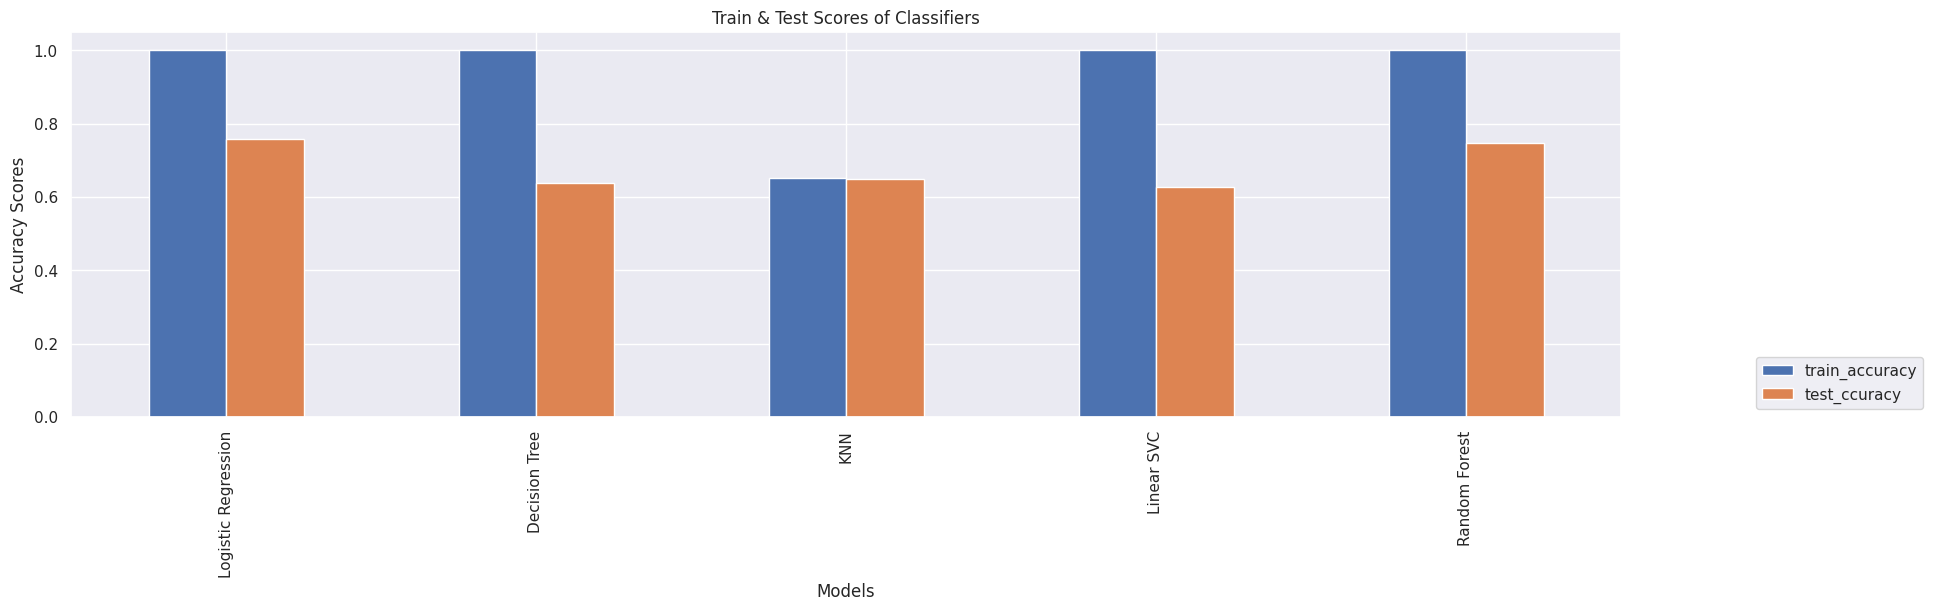

In [190]:
ax=result.plot(kind="bar",figsize=(20,5))
ax.set_xticks(result.index)
ax.set_xticklabels(result.model,rotation=90)
plt.title('Train & Test Scores of Classifiers')
plt.xlabel('Models')
plt.ylabel('Accuracy Scores')
plt.legend(loc=4 , bbox_to_anchor=(1.2, 0))
plt.show();

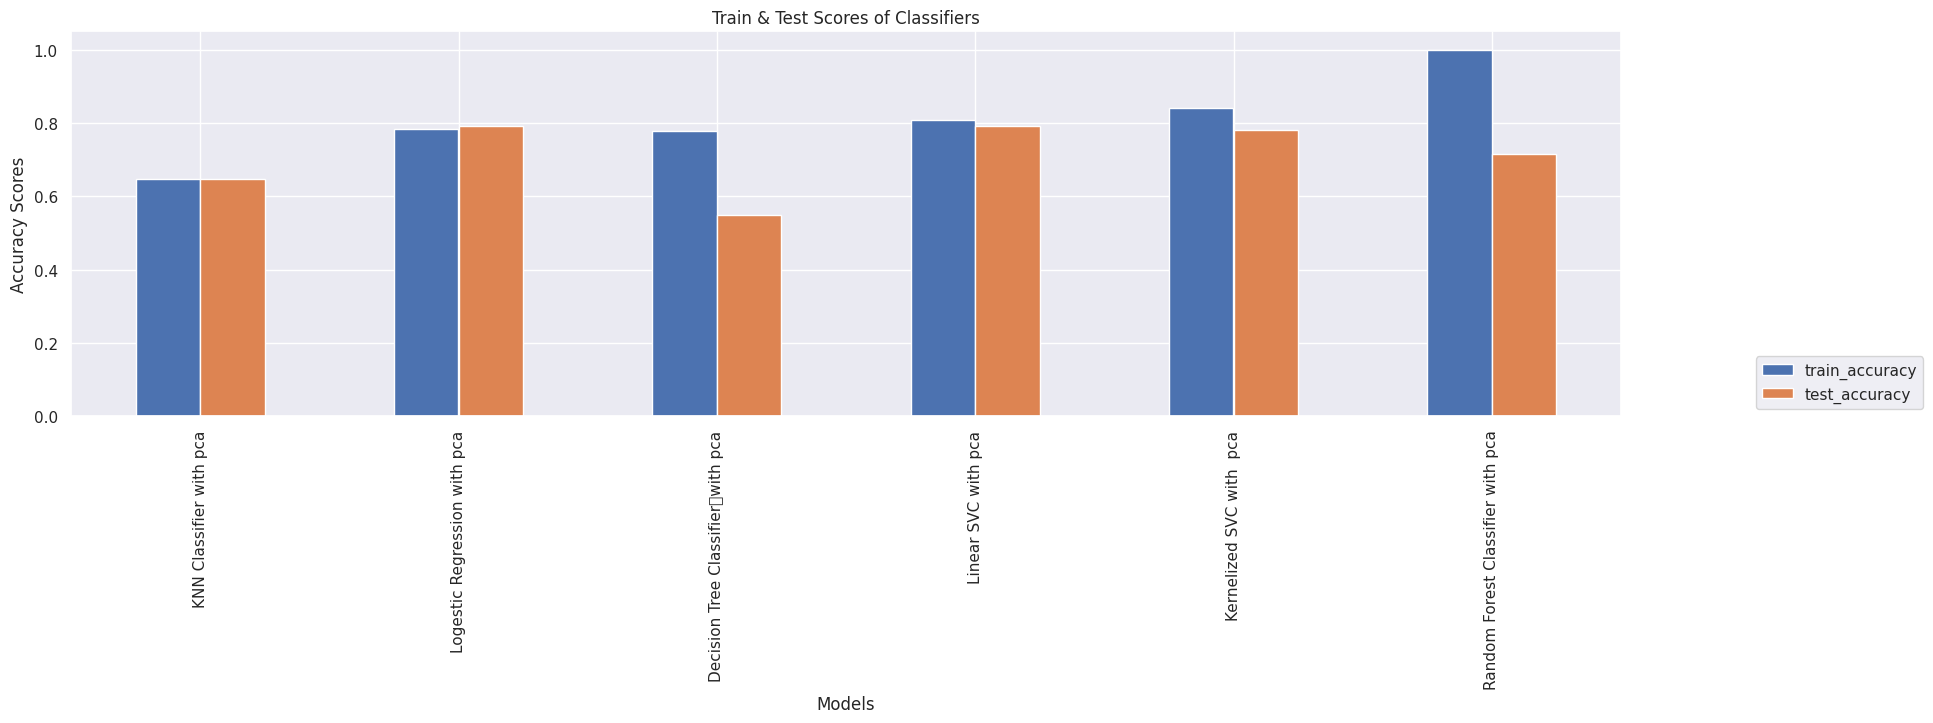

In [189]:
ax=result_with_pca.plot(kind="bar",figsize=(20,5))
ax.set_xticks(result_with_pca.index)
ax.set_xticklabels(result_with_pca.model,rotation=90)
plt.title('Train & Test Scores of Classifiers')
plt.xlabel('Models')
plt.ylabel('Accuracy Scores')
plt.legend(loc=4 , bbox_to_anchor=(1.2, 0))
plt.show();